In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

print("Everything is ready")

Everything is ready


In [ ]:
from google.colab import files

print("Choose your CONTENT image")
content_upload = files.upload()

content_path = list(content_upload.keys())[0]
print("Content image uploaded:", content_path)

Choose your CONTENT image


Saving Screenshot (2).png to Screenshot (2).png
Content image uploaded: Screenshot (2).png


In [ ]:
print("Choose your STYLE image")
style_upload = files.upload()

style_path = list(style_upload.keys())[0]
print("Style image uploaded:", style_path)

Choose your STYLE image


Saving dashboard.png to dashboard (1).png
Style image uploaded: dashboard (1).png


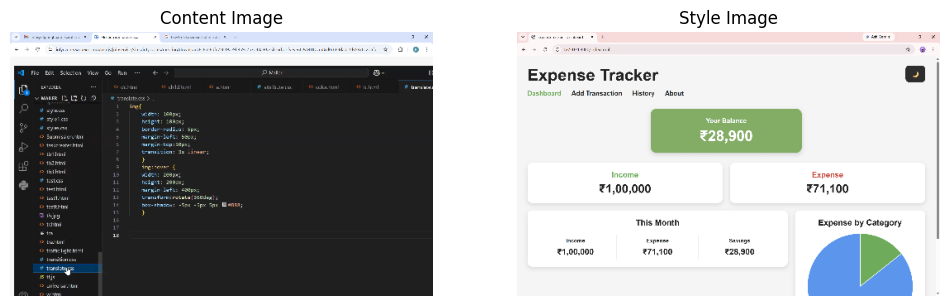

In [ ]:
def load_image(path, max_dim=512):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=3)
    image = tf.image.convert_image_dtype(image, tf.float32)

    shape = tf.cast(tf.shape(image)[:-1], tf.float32)
    long_dimension = max(shape)
    scale = max_dim / long_dimension

    new_shape = tf.cast(shape * scale, tf.int32)
    image = tf.image.resize(image, new_shape)

    return image[tf.newaxis, :]


content_image = load_image(content_path)
style_image = load_image(style_path)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(content_image[0])
plt.title("Content Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(style_image[0])
plt.title("Style Image")
plt.axis("off")

plt.show()

In [ ]:
vgg = tf.keras.applications.VGG19(
    include_top=False,
    weights="imagenet"
)

vgg.trainable = False

style_layers = [
    "block1_conv1",
    "block2_conv1",
    "block3_conv1",
    "block4_conv1",
    "block5_conv1"
]

content_layers = [
    "block5_conv2"
]

style_outputs = [
    vgg.get_layer(layer_name).output
    for layer_name in style_layers
]

content_outputs = [
    vgg.get_layer(layer_name).output
    for layer_name in content_layers
]

model_outputs = style_outputs + content_outputs

style_content_model = tf.keras.Model(
    vgg.input,
    model_outputs
)

print("VGG19 model loaded")

VGG19 model loaded


In [ ]:
def preprocess_image(image):
    image = image * 255
    return tf.keras.applications.vgg19.preprocess_input(image)


def gram_matrix(features):
    result = tf.linalg.einsum(
        "bijc,bijd->bcd",
        features,
        features
    )

    input_shape = tf.shape(features)
    number_of_locations = tf.cast(
        input_shape[1] * input_shape[2],
        tf.float32
    )

    return result / number_of_locations


def extract_features(image):
    image = preprocess_image(image)
    outputs = style_content_model(image)

    style_features = outputs[:len(style_layers)]
    content_features = outputs[len(style_layers):]

    style_features = [
        gram_matrix(feature)
        for feature in style_features
    ]

    return {
        "style": style_features,
        "content": content_features
    }


style_targets = extract_features(style_image)
content_targets = extract_features(content_image)

print("Image features extracted")

Image features extracted


In [ ]:
generated_image = tf.Variable(
    content_image,
    dtype=tf.float32
)

style_weight = 1e-3
content_weight = 1e4

optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.02
)


def calculate_loss(outputs):
    style_outputs = outputs["style"]
    content_outputs = outputs["content"]

    style_loss = tf.add_n([
        tf.reduce_mean(
            (style_outputs[i] - style_targets["style"][i]) ** 2
        )
        for i in range(len(style_layers))
    ])

    style_loss = style_loss * style_weight / len(style_layers)

    content_loss = tf.add_n([
        tf.reduce_mean(
            (content_outputs[i] - content_targets["content"][i]) ** 2
        )
        for i in range(len(content_layers))
    ])

    content_loss = content_loss * content_weight / len(content_layers)

    return style_loss + content_loss

In [ ]:
@tf.function
def train_step(image):
    with tf.GradientTape() as tape:
        outputs = extract_features(image)
        loss = calculate_loss(outputs)

    gradients = tape.gradient(loss, image)
    optimizer.apply_gradients([
        (gradients, image)
    ])

    image.assign(tf.clip_by_value(image, 0.0, 1.0))

    return loss


number_of_steps = 400

for step in range(number_of_steps):
    loss = train_step(generated_image)

    if (step + 1) % 50 == 0:
        print(
            "Step:",
            step + 1,
            "Loss:",
            float(loss)
        )

Step: 50 Loss: 34341432.0
Step: 100 Loss: 23403194.0
Step: 150 Loss: 19372352.0
Step: 200 Loss: 17078468.0
Step: 250 Loss: 15433046.0
Step: 300 Loss: 16486074.0
Step: 350 Loss: 13743325.0
Step: 400 Loss: 12505840.0


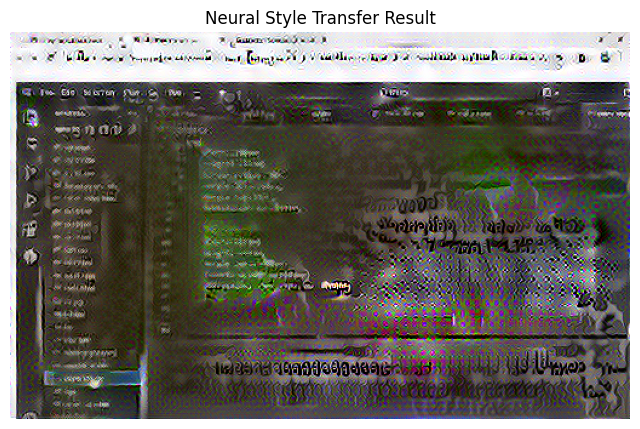

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
final_image = generated_image[0]

plt.figure(figsize=(8, 8))
plt.imshow(final_image)
plt.title("Neural Style Transfer Result")
plt.axis("off")
plt.show()

tf.keras.utils.save_img(
    "neural_style_transfer_result.png",
    final_image
)

files.download("neural_style_transfer_result.png")